Machine learning

- Supervised learning (model dilatih menggunakan data yang berlabel)
- unsupervised learning (model dilatih menggunakan data yang tidak berlabel) // fokus untuk mengkategorikan atau segmentasi

Supervised learning : 
1. linear regression
2. Decision tree
3. Random forest 
4. K-Nearest Neighbors

Unsupervised learning : 
1. K-Means

Linear regression

In [370]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import MinMaxScaler

In [371]:
np.random.seed(42)

data_size = 50
experience = np.random.randint(1, 21, size=data_size)
education = np.random.randint(1, 5, size=data_size)
noise = np.random.normal(0, 500000, size=data_size)
salary = np.round(1000000 * experience + 500000 * education + noise).astype(int)

df = pd.DataFrame({
    "Experience" : experience, 
    "Education" : education, 
    "Salary" : salary
})

df.head()

,Experience,Education,Salary
0,7,4,8661539
1,20,4,22305838
2,15,2,16515500
3,11,2,12465640
4,8,2,8580391


In [372]:
x = df[["Experience", "Education"]] # fitur
y = df[["Salary"]] # target 

scaler_x = MinMaxScaler() 
x_scaled = scaler_x.fit_transform(x)

scaler_y = MinMaxScaler()
y_norm = scaler_y.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_norm, test_size=0.3, random_state=42)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 35, x_test = 15
y_train = 35, y_test = 15


In [373]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

df_new = pd.DataFrame(x_test, columns=["Experience", "Education"])
df_new["y_pred"] = y_pred
df_new["y_test"] = y_test
df_new

,Experience,Education,y_pred,y_test
0,0.578947,1.000000,0.578996,0.615524
1,1.000000,1.000000,0.977517,1.000000
2,0.315789,1.000000,0.329921,0.372257
3,0.105263,0.000000,0.057854,0.071402
4,0.578947,1.000000,0.578996,0.566238
5,0.157895,0.666667,0.156207,0.128623
6,1.000000,0.000000,0.904711,0.904527
7,0.578947,1.000000,0.578996,0.574762
8,0.315789,0.333333,0.281383,0.266700
9,0.842105,0.666667,0.803803,0.841638


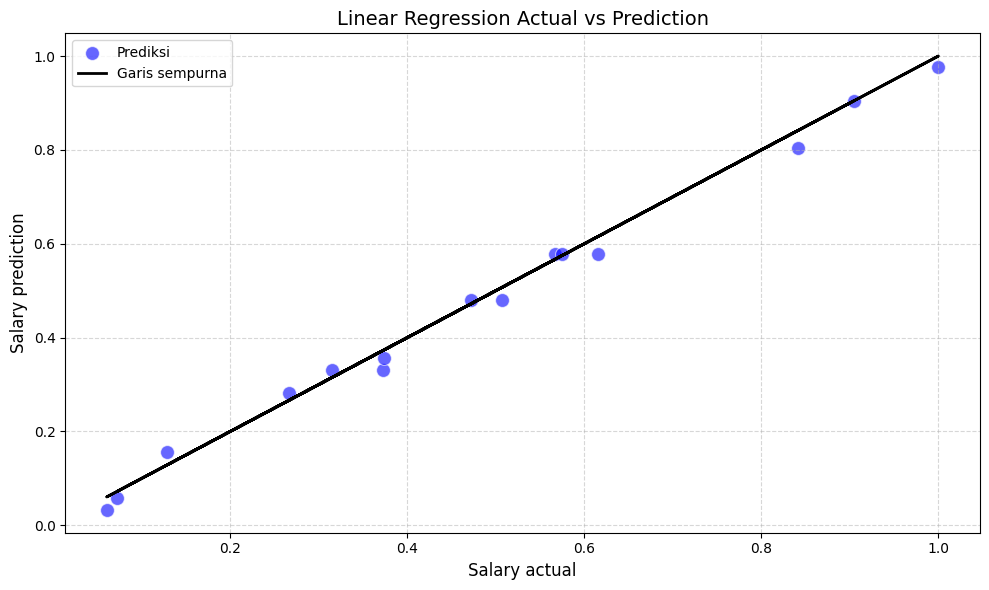

In [374]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, color="blue", alpha=0.6, s=100, label="Prediksi")
plt.plot(y_test, y_test, color="black", linewidth=2, label = "Garis sempurna")
plt.xlabel("Salary actual", fontsize = 12)
plt.ylabel("Salary prediction", fontsize = 12)
plt.title("Linear Regression Actual vs Prediction", fontsize = 14)
plt.legend()
plt.grid(True, linestyle="--", alpha = 0.5)
plt.tight_layout() 
plt.show()

In [375]:
model.score(x_test, y_test)

0.992814325133279

In [376]:
new_data = pd.DataFrame({
    "Experience" : [1, 10, 5],
    "Education" : [1, 2, 2]
})

data_scaled = scaler_x.transform(new_data)

new_pred = model.predict(data_scaled)
pred = scaler_y.inverse_transform(new_pred.reshape(-1, 1))

new_data["Salary"] = np.round(pred.ravel()).astype(int)

new_data

,Experience,Education,Salary
0,1,1,1332625
1,10,2,10928150
2,5,2,5871047


ASSIGNMENT

In [377]:
covid = pd.read_csv("covid19.csv")
covid

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,NaN,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,NaN,266387,NaN,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,NaN,266387,NaN,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,NaN,266387,NaN,5740


In [378]:
covid.isnull().sum()
covid.fillna(0, inplace=True)
covid.isnull().sum()

Date_reported        0
Country_code         0
Country              0
Continent            0
WHO_region           0
New_cases            0
Cumulative_cases     0
New_deaths           0
Cumulative_deaths    0
dtype: int64

In [379]:
x = covid[["Cumulative_cases", "New_deaths", "Country_code"]]
y = covid[["Cumulative_deaths"]]

Preprocessing

In [380]:
x = pd.get_dummies(x, columns=["Country_code"], drop_first=True)

covid_x = MinMaxScaler()
x[["Cumulative_cases", "New_deaths"]] = covid_x.fit_transform(x[["Cumulative_cases", "New_deaths"]])

covid_y = MinMaxScaler()
y = covid_y.fit_transform(y).ravel()
x

,Cumulative_cases,New_deaths,Country_code_AD,Country_code_AE,Country_code_AF,Country_code_AG,Country_code_AI,Country_code_AL,Country_code_AM,Country_code_AO,...,Country_code_XXG,Country_code_XXH,Country_code_XXI,Country_code_XXJ,Country_code_XXL,Country_code_YE,Country_code_YT,Country_code_ZA,Country_code_ZM,Country_code_ZW
0,0.000000,0.067137,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,0.000000,0.067137,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0.000000,0.067137,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,0.000000,0.067137,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,0.000000,0.067137,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58555,0.002575,0.067137,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
58556,0.002575,0.067137,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
58557,0.002575,0.067137,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
58558,0.002575,0.067137,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [381]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 46848, x_test = 11712
y_train = 46848, y_test = 11712


In [382]:
covid_model = LinearRegression()
covid_model.fit(x_train, y_train)

y_pred = covid_model.predict(x_test)
y_pred


array([3.33629703e-02, 3.19488833e-03, 7.02873503e-04, ...,
       7.66938482e-06, 7.22536353e-05, 4.37540252e-04])

In [383]:
covid_model.score(x_test, y_test)

0.8908931019828888